In [ ]:
import pandas as pd
from vacoda.io.paths import get_processed_data_file_path

df_base = pd.read_parquet(get_processed_data_file_path())
print("Shape of the base dataframe:", df_base.shape)
df_base.head()

Shape of the base dataframe: (25589, 57)


,record_id,hs_code_short,reporter_code,partner_code,commodity_code,year,flow_code,unit_code,value_raw,reported_currency,...,unit_short_name,unit_description,estimation_description,value_norm,is_estimated,quantity_estimated,weight_estimated,year_date,hs_mismatch,calc_price_per_kg
0,80630069,H3,100,124,441012,2011,1,8,319186,BGN,...,NaN,NaN,no estimation,227172.017478,False,False,False,2011-01-01,False,0.313385
1,80630182,H3,100,156,441012,2011,1,8,171644,BGN,...,NaN,NaN,no estimation,122162.982612,False,False,False,2011-01-01,False,0.374848
2,80630489,H3,100,196,441012,2011,2,8,518550,BGN,...,NaN,NaN,no estimation,369191.524950,False,False,False,2011-01-01,False,0.315076
3,444829158,H5,100,196,441012,2018,2,8,684637,NaN,...,NaN,NaN,no estimation,684637.000000,False,False,False,2018-01-01,False,0.450615
4,444840706,H5,100,203,441012,2018,1,8,10976,NaN,...,NaN,NaN,no estimation,10976.000000,False,False,False,2018-01-01,False,0.488691


In [2]:
df_base.columns.to_list()

['record_id',
 'hs_code_short',
 'reporter_code',
 'partner_code',
 'commodity_code',
 'year',
 'flow_code',
 'unit_code',
 'value_raw',
 'reported_currency',
 'conversion_factor',
 'netweight_kg',
 'sup_quantity',
 'estimation_code',
 'reported_hs_code_short',
 'CD_HT',
 'partner_source',
 'valuation',
 'CD_FlowsInDataset',
 'CD_UnitMult',
 'CD_Decimals',
 'CD_IDUpload',
 'CD_IDReporter',
 'CD_IDPartner',
 'CD_IDCommodity',
 'CD_IDUnit',
 'CD_as_reported',
 'price_per_kg',
 'CD_ActionType',
 'reporter_country_code',
 'reporter_country_name',
 'reporter_country_iso2',
 'reporter_country_iso3',
 'reporter_country_valid_from',
 'reporter_country_valid_until',
 'partner_country_code',
 'partner_country_name',
 'partner_country_iso2',
 'partner_country_iso3',
 'partner_country_valid_from',
 'partner_country_valid_until',
 'hs_valid_from',
 'hs_valid_until',
 'hs_version_name',
 'commodity_description',
 'flow_description',
 'flow_category',
 'unit_short_name',
 'unit_description',
 'estima

## Investigate ID related Features

In [3]:
## collect all columns that have CD_ in their name
Id_columns = [col for col in df_base.columns if "CD_" in col]
Id_columns

['CD_HT',
 'CD_FlowsInDataset',
 'CD_UnitMult',
 'CD_Decimals',
 'CD_IDUpload',
 'CD_IDReporter',
 'CD_IDPartner',
 'CD_IDCommodity',
 'CD_IDUnit',
 'CD_as_reported',
 'CD_ActionType']

In [4]:
## check how many unique values are in each of the ID columns
for col in Id_columns:
    print(f"{col}: {df_base[col].nunique()}")

CD_HT: 1
CD_FlowsInDataset: 7
CD_UnitMult: 1
CD_Decimals: 1
CD_IDUpload: 190
CD_IDReporter: 309
CD_IDPartner: 404
CD_IDCommodity: 6
CD_IDUnit: 3
CD_as_reported: 1
CD_ActionType: 2


In [5]:
## Check if Id_columns are important or shall be deleted for modeling
for col in Id_columns:
    print(f"{col} - missing values: {df_base[col].isna().sum()}")

CD_HT - missing values: 12642
CD_FlowsInDataset - missing values: 12695
CD_UnitMult - missing values: 12642
CD_Decimals - missing values: 12642
CD_IDUpload - missing values: 0
CD_IDReporter - missing values: 0
CD_IDPartner - missing values: 0
CD_IDCommodity - missing values: 0
CD_IDUnit - missing values: 0
CD_as_reported - missing values: 12642
CD_ActionType - missing values: 0


In [ ]:
import importlib
import vacoda.visualization.distribution as dist
importlib.reload(dist)
dist.save_id_column_distribution_plots(df_base, Id_columns)

Saving ID column distribution plots to: E:\Projects\VANDA\output\figures


In [7]:
Id_columns

['CD_HT',
 'CD_FlowsInDataset',
 'CD_UnitMult',
 'CD_Decimals',
 'CD_IDUpload',
 'CD_IDReporter',
 'CD_IDPartner',
 'CD_IDCommodity',
 'CD_IDUnit',
 'CD_as_reported',
 'CD_ActionType']

In [8]:
## Lets find which of the columns in Id_columns are constant values or only Null values and store them in a list
constant_or_null_columns = []
for col in Id_columns:
    unique_values = df_base[col].dropna().unique()
    if len(unique_values) == 0:
        print(f"{col} has only Null values.")
        constant_or_null_columns.append(col)
    elif len(unique_values) == 1:
        print(f"{col} has only one unique value: {unique_values[0]}")
        constant_or_null_columns.append(col)

    else:
        print(f"{col} has {len(unique_values)} unique values.")
constant_or_null_columns

CD_HT has only one unique value: 0.0
CD_FlowsInDataset has 7 unique values.
CD_UnitMult has only one unique value: 1.0
CD_Decimals has only one unique value: 1.0
CD_IDUpload has 190 unique values.
CD_IDReporter has 309 unique values.
CD_IDPartner has 404 unique values.
CD_IDCommodity has 6 unique values.
CD_IDUnit has 3 unique values.
CD_as_reported has only one unique value: 1.0
CD_ActionType has 2 unique values.


['CD_HT', 'CD_UnitMult', 'CD_Decimals', 'CD_as_reported']

In [9]:
## Lets remove the ID columns and check the shape of the dataframe again
cols_to_drop = constant_or_null_columns + ['CD_IDReporter', 'CD_IDPartner']
df_base = df_base.drop(columns=cols_to_drop)

In [10]:
df_base.groupby("reporter_country_name")["value_norm"].sum().sort_values(ascending=False).head(10)

reporter_country_name
USA                   2.275809e+10
Canada                2.234471e+10
Germany               6.170379e+09
Czechia               2.923462e+09
Latvia                2.696766e+09
Belgium               2.572892e+09
Romania               2.547556e+09
United Kingdom        2.479245e+09
Poland                2.144581e+09
Russian Federation    1.905039e+09
Name: value_norm, dtype: float64

In [ ]:
df_base["hs_mismatch"].value_counts(dropna=False)

In [ ]:
df_base["is_estimated"].value_counts(dropna=False)

Saving distribution plot for price_per_kg to: E:\Projects\VANDA\output\figures


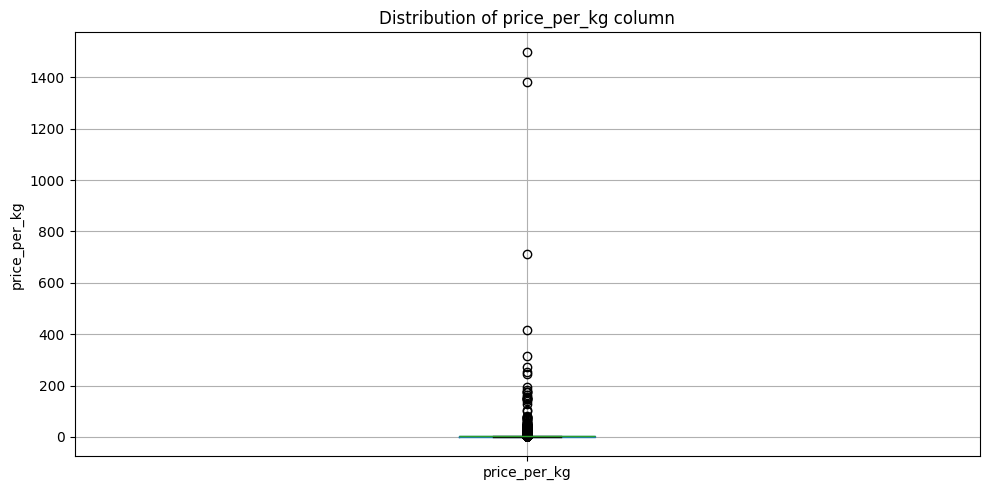

In [ ]:
import vacoda.visualization.distribution as dist
dist.plot_bar_distribution(df_base, "price_per_kg", title="Distribution of price_per_kg column")
#df_base["price_per_kg"].describe()

In [3]:
df_base["calc_price_per_kg"].describe()

count    25191.000000
mean         3.109182
std         86.996572
min          0.000000
25%          0.404555
50%          0.536989
75%          0.813148
max       8305.000000
Name: calc_price_per_kg, dtype: float64

In [3]:
df_base.loc[
    df_base["hs_mismatch"],
    [
        "record_id",
        "year",
        "hs_code_short",
        "hs_version_name",
        "commodity_code",
        "commodity_description",
        "reporter_country_name",
        "partner_country_name",
    ],
].head(20)

,record_id,year,hs_code_short,hs_version_name,commodity_code,commodity_description,reporter_country_name,partner_country_name
141,444005748,2017,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Burundi,United Arab Emirates
216,445130861,2018,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Burundi,United Arab Emirates
741,443253417,2017,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Burundi,China
778,444429296,2018,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Burundi,China
916,443558710,2017,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Cameroon,China
962,445394872,2018,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Cabo Verde,Portugal
1033,87528986,2012,H3,HS2007,441012,"Oriented strand board (OSB) of wood, whether/...",Sri Lanka,China
2317,443861363,2017,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Congo,France
2525,446087325,2017,H4,HS2012,441012,"Oriented strand board (OSB) of wood, whether o...",Comoros,China
4068,104391494,2013,H3,HS2007,441012,"Oriented strand board (OSB) of wood, whether/...",Ethiopia,China


In [4]:
df_base.loc[df_base["hs_mismatch"], "year"].value_counts().sort_index()

year
2012    146
2013     70
2014     37
2015      8
2016     10
2017    178
2018    110
2019     77
2020     37
2021     15
2022     45
Name: count, dtype: int64

In [5]:
df_base.loc[df_base["hs_mismatch"], "hs_code_short"].value_counts()

hs_code_short
H4    406
H3    285
H5     42
Name: count, dtype: int64

In [6]:
df_base["price_per_kg"].quantile([0.90, 0.95, 0.99, 0.995, 0.999])

0.900     2.901851
0.950     3.422419
0.990     7.385057
0.995    17.832832
0.999    77.779634
Name: price_per_kg, dtype: float64

In [7]:
df_base.nlargest(20, "price_per_kg")[
    [
        "record_id",
        "reporter_country_name",
        "partner_country_name",
        "year",
        "commodity_code",
        "commodity_description",
        "value_norm",
        "netweight_kg",
        "sup_quantity",
        "unit_short_name",
        "is_estimated",
        "weight_estimated",
        "quantity_estimated",
        "price_per_kg",
    ]
]

,record_id,reporter_country_name,partner_country_name,year,commodity_code,commodity_description,value_norm,netweight_kg,sup_quantity,unit_short_name,is_estimated,weight_estimated,quantity_estimated,price_per_kg
20269,76976154,Slovakia,Germany,2009,441012,"Oriented strand board (OSB) of wood, whether/...",1.398661e+00,1500.0,1500.0,NaN,False,False,False,1500.000000
20256,449981176,Singapore,Romania,2021,441012,"Oriented strand board (OSB) of wood, whether o...",5.617300e+04,77648502.0,77648502.0,NaN,True,True,True,1382.310042
16373,449558533,Bolivia (Plurinational State of),Brazil,2021,441012,"Oriented strand board (OSB) of wood, whether o...",5.627190e+05,399908763.0,399908763.0,NaN,True,True,True,710.672224
23721,447495613,Bolivia (Plurinational State of),Chile,2019,441012,"Oriented strand board (OSB) of wood, whether o...",2.363300e+04,9838069.0,9838069.0,NaN,True,True,True,416.285237
12830,443683278,Netherlands,France,2017,441012,"Oriented strand board (OSB) of wood, whether o...",6.731000e+03,2120060.0,2120060.0,NaN,False,False,False,314.969544
12382,449856886,Mozambique,South Africa,2021,441012,"Oriented strand board (OSB) of wood, whether o...",4.645000e+04,12588622.0,12588622.0,NaN,True,True,True,271.014467
22134,447445588,Netherlands,Spain,2019,441012,"Oriented strand board (OSB) of wood, whether o...",2.920000e+03,735274.0,735274.0,NaN,True,True,True,251.806164
25584,448470815,Uzbekistan,Italy,2020,441012,"Oriented strand board (OSB) of wood, whether o...",7.910000e+03,1931137.0,1931137.0,NaN,True,True,True,244.138685
20253,450005023,Singapore,Netherlands,2021,441012,"Oriented strand board (OSB) of wood, whether o...",2.042500e+04,3959670.0,3959670.0,NaN,True,True,True,193.863892
22892,450056608,Sweden,Denmark,2021,441012,"Oriented strand board (OSB) of wood, whether o...",1.160000e+02,21000.0,21000.0,NaN,False,False,False,181.034483


In [8]:
high_cutoff = df_base.loc[df_base["price_per_kg"].notna(), "price_per_kg"].quantile(0.99)
low_cutoff = df_base.loc[df_base["price_per_kg"].notna(), "price_per_kg"].quantile(0.01)

df_base["missing_netweight"] = df_base["netweight_kg"].isna()
df_base["zero_or_negative_netweight"] = df_base["netweight_kg"].fillna(0) <= 0
df_base["very_high_price_per_kg"] = df_base["price_per_kg"] > high_cutoff
df_base["very_low_price_per_kg"] = df_base["price_per_kg"] < low_cutoff

In [9]:
flag_cols = [
    "hs_mismatch",
    "is_estimated",
    "missing_netweight",
    "zero_or_negative_netweight",
    "very_high_price_per_kg",
    "very_low_price_per_kg",
]

df_base["quality_issue_count"] = df_base[flag_cols].sum(axis=1)

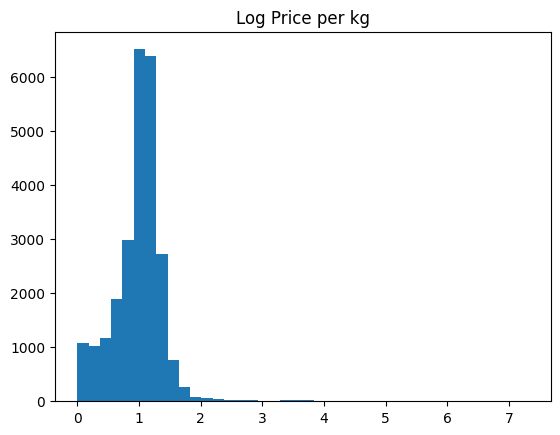

In [10]:
import numpy as np
import matplotlib.pyplot as plt
plt.figure()
plt.hist(np.log1p(df_base["price_per_kg"].dropna()), bins=40)
plt.title("Log Price per kg")
plt.show()

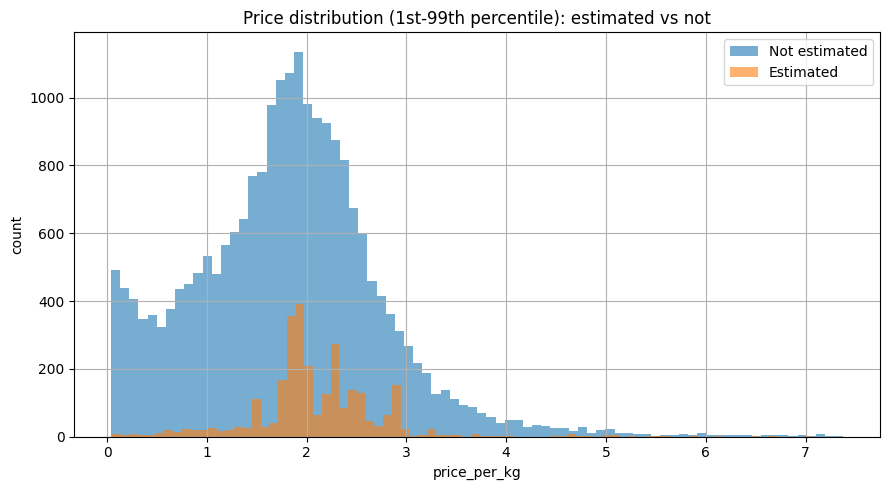

In [11]:
import matplotlib.pyplot as plt

# Keep central mass only for visualization (exclude extreme outliers)
price = df_base["price_per_kg"]
low, high = price.quantile([0.01, 0.99])
view = df_base[price.between(low, high, inclusive="both") & price.notna()]

plt.figure(figsize=(9, 5))
view.loc[~view["is_estimated"], "price_per_kg"].hist(
    bins=80, alpha=0.6, label="Not estimated"
 )
view.loc[view["is_estimated"], "price_per_kg"].hist(
    bins=80, alpha=0.6, label="Estimated"
 )
plt.legend()
plt.title("Price distribution (1st-99th percentile): estimated vs not")
plt.xlabel("price_per_kg")
plt.ylabel("count")
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

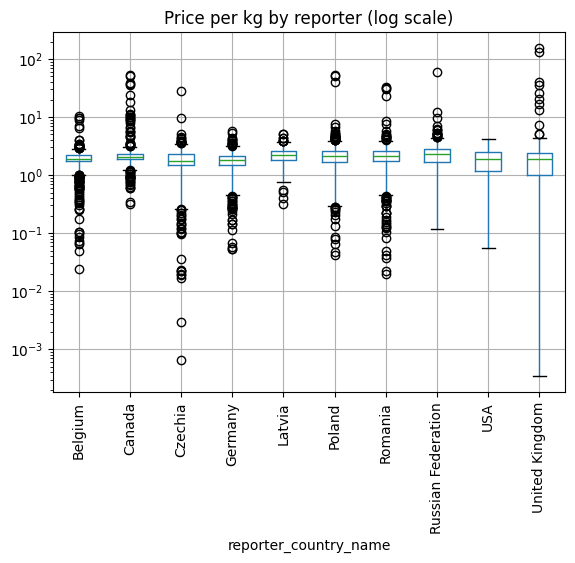

In [12]:
top_reporters = (
    df_base.groupby("reporter_country_name")["value_norm"].sum().nlargest(10).index
)

subset = df_base[df_base["reporter_country_name"].isin(top_reporters)]

plt.figure()
subset.boxplot(column="price_per_kg", by="reporter_country_name", rot=90)
plt.yscale("log")
plt.title("Price per kg by reporter (log scale)")
plt.suptitle("")
plt.show()

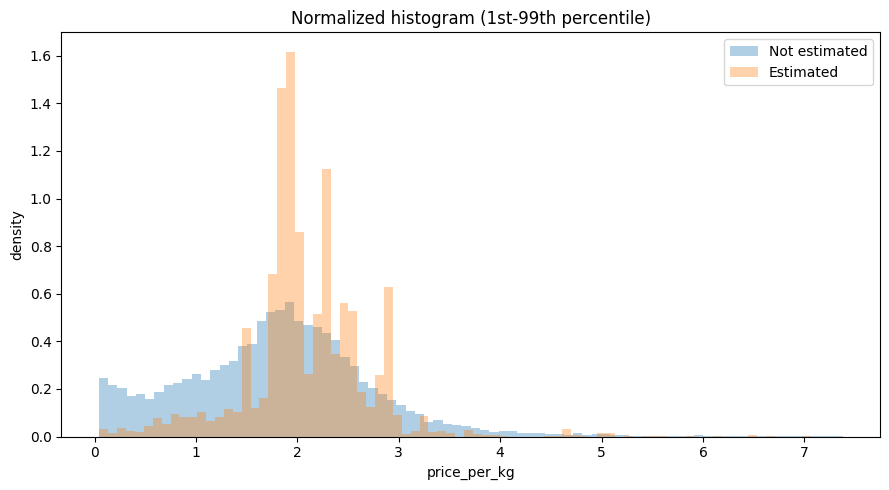

In [13]:
# Comparison Plot 1: normalized histogram (same trimmed window)
price = df_base["price_per_kg"]
low, high = price.quantile([0.01, 0.99])
view = df_base[price.between(low, high, inclusive="both") & price.notna()]

est = view.loc[view["is_estimated"], "price_per_kg"]
not_est = view.loc[~view["is_estimated"], "price_per_kg"]

plt.figure(figsize=(9, 5))
bins = 80
plt.hist(not_est, bins=bins, density=True, alpha=0.35, label="Not estimated")
plt.hist(est, bins=bins, density=True, alpha=0.35, label="Estimated")
plt.title("Normalized histogram (1st-99th percentile)")
plt.xlabel("price_per_kg")
plt.ylabel("density")
plt.legend()
plt.tight_layout()
plt.show()

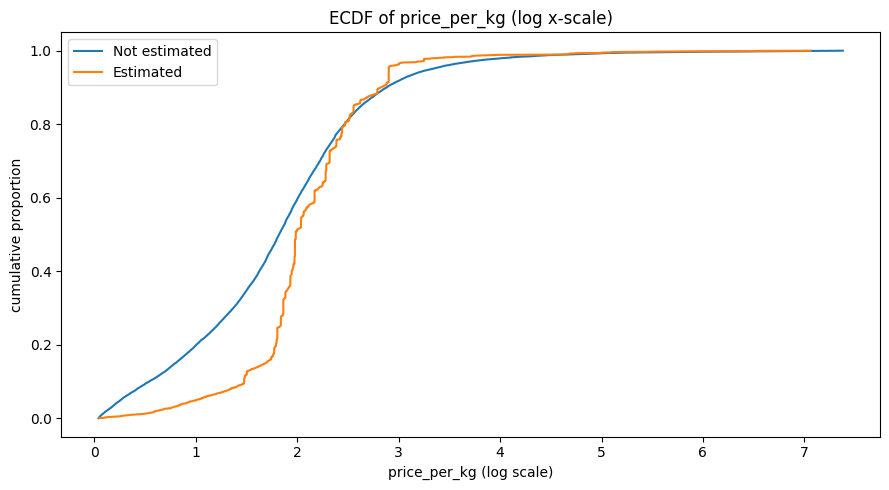

In [21]:
# Comparison Plot 2: ECDF (very good for skewed distributions)
import numpy as np

def ecdf(x):
    x = np.sort(np.asarray(x))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

x1, y1 = ecdf(not_est)
x2, y2 = ecdf(est)

plt.figure(figsize=(9, 5))
plt.plot(x1, y1, label="Not estimated")
plt.plot(x2, y2, label="Estimated")
    
plt.title("ECDF of price_per_kg (log x-scale)")
plt.xlabel("price_per_kg (log scale)")
plt.ylabel("cumulative proportion")
plt.legend()
plt.tight_layout()
plt.show()

<Figure size 700x500 with 0 Axes>

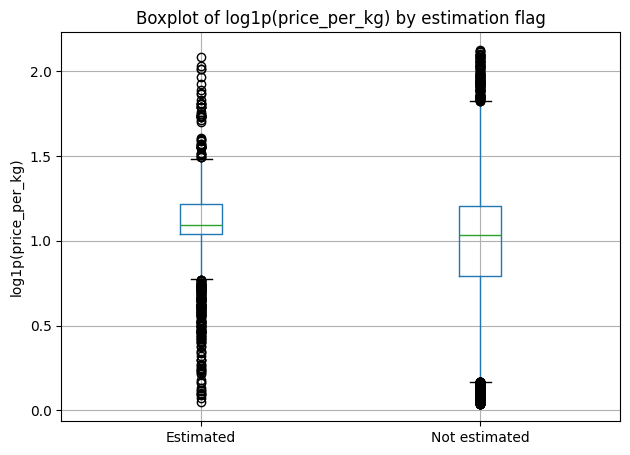

In [15]:
# Comparison Plot 3: boxplot on log1p scale
plot_df = view[["price_per_kg", "is_estimated"]].copy()
plot_df["group"] = np.where(plot_df["is_estimated"], "Estimated", "Not estimated")
plot_df["log_price"] = np.log1p(plot_df["price_per_kg"])

plt.figure(figsize=(7, 5))
plot_df.boxplot(column="log_price", by="group")
plt.title("Boxplot of log1p(price_per_kg) by estimation flag")
plt.suptitle("")
plt.xlabel("")
plt.ylabel("log1p(price_per_kg)")
plt.tight_layout()
plt.show()

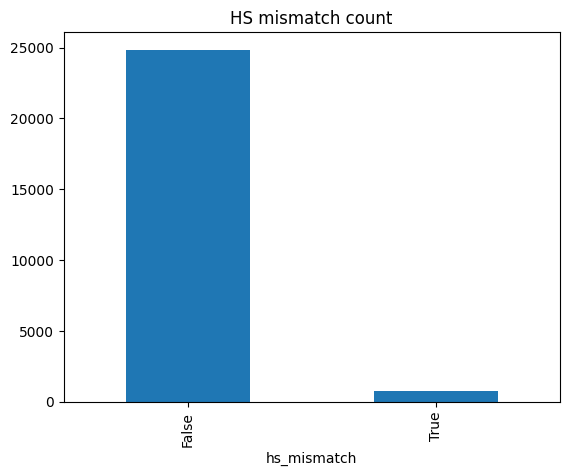

In [16]:
df_base["hs_mismatch"].value_counts().plot(kind="bar")
plt.title("HS mismatch count")
plt.show()

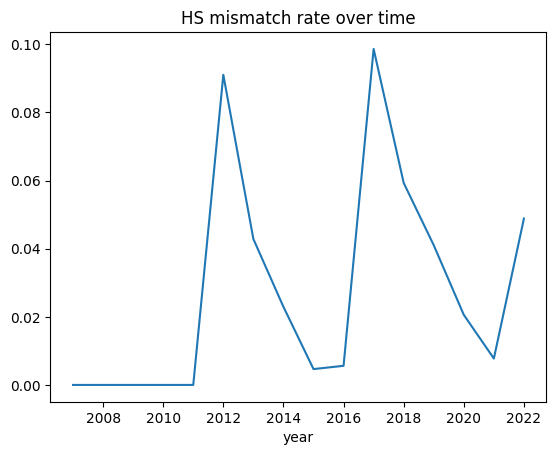

In [17]:
df_base.groupby("year")["hs_mismatch"].mean().plot()
plt.title("HS mismatch rate over time")
plt.show()

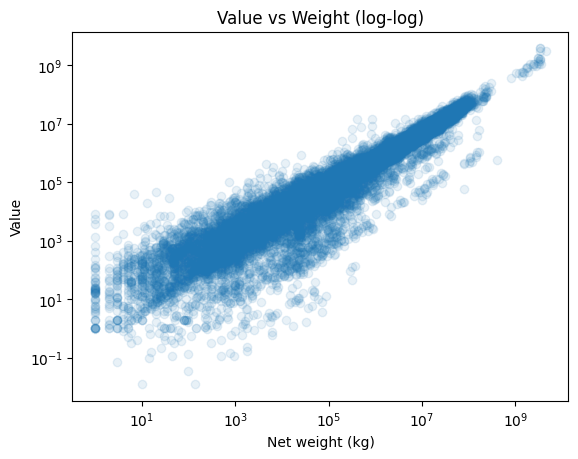

In [25]:
plt.figure()
plt.scatter(df_base["netweight_kg"], df_base["value_norm"], alpha=0.1)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Net weight (kg)")
plt.ylabel("Value")
plt.title("Value vs Weight (log-log)")
plt.show()

In [19]:
df_base.columns.to_list()

['record_id',
 'hs_code_short',
 'reporter_code',
 'partner_code',
 'commodity_code',
 'year',
 'flow_code',
 'unit_code',
 'value_raw',
 'reported_currency',
 'conversion_factor',
 'netweight_kg',
 'sup_quantity',
 'estimation_code',
 'reported_hs_code_short',
 'CD_HT',
 'partner_source',
 'valuation',
 'CD_FlowsInDataset',
 'CD_UnitMult',
 'CD_Decimals',
 'CD_IDUpload',
 'CD_IDReporter',
 'CD_IDPartner',
 'CD_IDCommodity',
 'CD_IDUnit',
 'CD_as_reported',
 'price_per_kg',
 'CD_ActionType',
 'reporter_country_code',
 'reporter_country_name',
 'reporter_country_iso2',
 'reporter_country_iso3',
 'reporter_country_valid_from',
 'reporter_country_valid_until',
 'partner_country_code',
 'partner_country_name',
 'partner_country_iso2',
 'partner_country_iso3',
 'partner_country_valid_from',
 'partner_country_valid_until',
 'hs_valid_from',
 'hs_valid_until',
 'hs_version_name',
 'commodity_description',
 'flow_description',
 'flow_category',
 'unit_short_name',
 'unit_description',
 'estima

In [24]:
df_base.columns.to_list()

['record_id',
 'hs_code_short',
 'reporter_code',
 'partner_code',
 'commodity_code',
 'year',
 'flow_code',
 'unit_code',
 'value_raw',
 'reported_currency',
 'conversion_factor',
 'netweight_kg',
 'sup_quantity',
 'estimation_code',
 'reported_hs_code_short',
 'CD_HT',
 'partner_source',
 'valuation',
 'CD_FlowsInDataset',
 'CD_UnitMult',
 'CD_Decimals',
 'CD_IDUpload',
 'CD_IDReporter',
 'CD_IDPartner',
 'CD_IDCommodity',
 'CD_IDUnit',
 'CD_as_reported',
 'price_per_kg',
 'CD_ActionType',
 'reporter_country_code',
 'reporter_country_name',
 'reporter_country_iso2',
 'reporter_country_iso3',
 'reporter_country_valid_from',
 'reporter_country_valid_until',
 'partner_country_code',
 'partner_country_name',
 'partner_country_iso2',
 'partner_country_iso3',
 'partner_country_valid_from',
 'partner_country_valid_until',
 'hs_valid_from',
 'hs_valid_until',
 'hs_version_name',
 'commodity_description',
 'flow_description',
 'flow_category',
 'unit_short_name',
 'unit_description',
 'estima

## IMTS 2010 Partner Attribution Analysis

Verify partner attribution compliance (partner_code) with IMTS 2010 recommendations:
- **Imports**: country of origin (primary) + country of consignment (secondary)
- **Exports**: country of last known destination (primary) + country of consignment (secondary)

In [ ]:
import importlib
import vacoda.visualization.distribution as dist
importlib.reload(dist)

# Run IMTS 2010 partner attribution analysis
summary = dist.analyze_imts2010_partner_attribution(df_base)

Analyzing IMTS 2010 partner attribution compliance
Saving plots to: E:\Projects\VANDA\output\figures

Available columns in dataset:
  - CD_FlowsInDataset
  - CD_IDPartner
  - CD_IDReporter
  - CD_as_reported
  - flow_category
  - flow_code
  - flow_description
  - partner_code
  - partner_country_code
  - partner_country_iso2
  - partner_country_iso3
  - partner_country_name
  - partner_country_valid_from
  - partner_country_valid_until
  - partner_source
  - reported_currency
  - reported_hs_code_short
  - reporter_code
  - reporter_country_code
  - reporter_country_iso2
  - reporter_country_iso3
  - reporter_country_name
  - reporter_country_valid_from
  - reporter_country_valid_until

Identified key columns:
  partner: ['partner_code', 'partner_source', 'CD_IDPartner', 'partner_country_code', 'partner_country_name', 'partner_country_iso2', 'partner_country_iso3', 'partner_country_valid_from', 'partner_country_valid_until']

=== IMTS 2010 Partner Attribution Analysis ===
Total record